# Sprint 1: data cleaning and exploratory analysis

EarlySignal NG. This notebook covers the first sprint in section 3.9 of the write-up: clean the records, then look at how the three indicators relate to the outcome.

The bundled dataset is **synthetic**. Swap in real anonymised records to repeat the analysis.

Run it from the project root: `jupyter notebook notebooks/01_eda.ipynb` (needs `pip install notebook matplotlib`).

In [1]:
import sys, pathlib
root = pathlib.Path.cwd() if (pathlib.Path.cwd() / 'ml').exists() else pathlib.Path.cwd().parent
sys.path.insert(0, str(root))
import pandas as pd, matplotlib.pyplot as plt
from ml import pipeline
raw = pd.read_csv(pipeline.ensure_dataset())
raw.head()

,ref_code,institution_type,state,zone,level,semester,ca_score,attendance_rate,previous_gpa,gpa_scale,outcome
0,NG-004945,Polytechnic,Kebbi,North West,HND 1,First,69.1,89.0,2.03,4.0,Pass
1,NG-004257,Polytechnic,Bauchi,North East,HND 2,First,71.8,83.0,2.58,4.0,Pass
2,NG-004304,University,Oyo,South West,200 Level,First,25.2,53.0,2.00,5.0,Under-perform
3,NG-002434,Polytechnic,Oyo,South West,ND 1,Second,75.9,95.0,2.25,4.0,Pass
4,NG-002574,University,Kano,North West,400 Level,Second,73.7,98.0,3.92,5.0,Pass


## 1. Cleaning (section 3.5)
Duplicates are removed. Records missing any of the three indicators are excluded, not estimated.

In [2]:
print('Missing values per column before cleaning:')
print(raw[['ca_score','attendance_rate','previous_gpa']].isna().sum())
print('Exact duplicate rows:', raw.duplicated().sum())
df, summary = pipeline.clean(raw)
pd.Series(summary)

Missing values per column before cleaning:
ca_score           65
attendance_rate    83
previous_gpa       79
dtype: int64
Exact duplicate rows: 120


rows_raw                 6120.0000
duplicates_removed        120.0000
missing_removed           217.0000
out_of_range_removed        0.0000
unknown_label_removed       0.0000
rows_used                5783.0000
under_perform            1557.0000
pass                     4226.0000
under_perform_share         0.2692
dtype: float64

## 2. Class balance

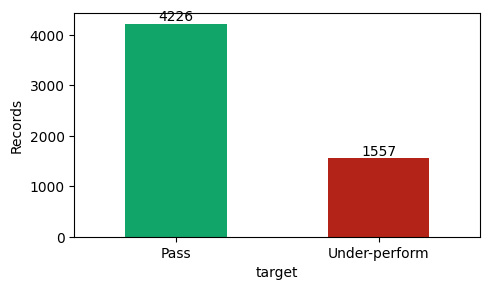

In [3]:
counts = df['target'].map({0:'Pass',1:'Under-perform'}).value_counts()
ax = counts.plot.bar(color=['#12A569','#B42318'], rot=0, figsize=(5,3))
ax.set_ylabel('Records'); ax.bar_label(ax.containers[0]); plt.tight_layout(); plt.show()

## 3. Each indicator against the outcome

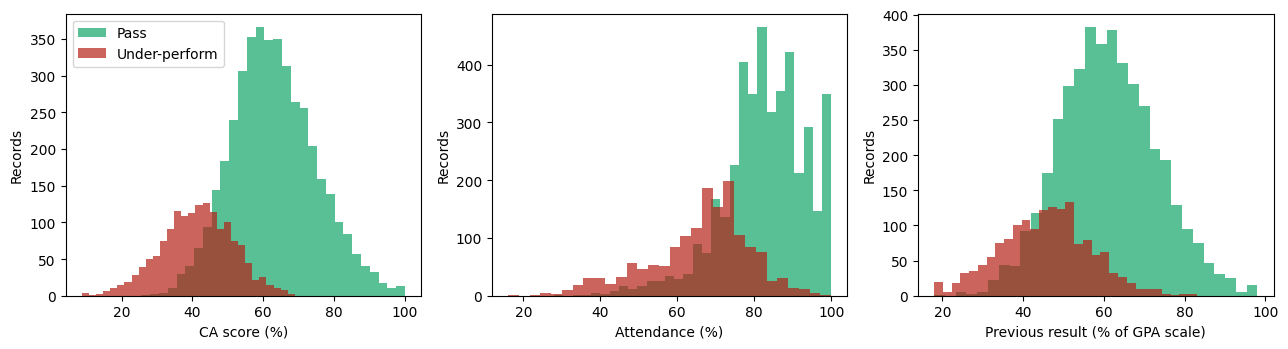

In [4]:
GREEN, RED = '#12A569', '#B42318'
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col, label in zip(axes, pipeline.FEATURES, ['CA score (%)', 'Attendance (%)', 'Previous result (% of GPA scale)']):
    ax.hist(df.loc[df.target==0, col], bins=30, alpha=.7, color=GREEN, label='Pass')
    ax.hist(df.loc[df.target==1, col], bins=30, alpha=.7, color=RED, label='Under-perform')
    ax.set_xlabel(label); ax.set_ylabel('Records')
axes[0].legend(); plt.tight_layout(); plt.show()

In [5]:
df.groupby(df['target'].map({0:'Pass',1:'Under-perform'}))[pipeline.FEATURES].mean().round(1)

,ca_score,attendance_rate,previous_result
target,,,
Pass,63.0,82.7,61.0
Under-perform,41.3,65.7,45.6


## 4. Correlations
Negative values mean higher figures go with a lower chance of under-performing.

In [6]:
df[pipeline.FEATURES + ['target']].corr().round(3)

,ca_score,attendance_rate,previous_result,target
ca_score,1.000,0.523,0.618,-0.647
attendance_rate,0.523,1.000,0.321,-0.547
previous_result,0.618,0.321,1.000,-0.503
target,-0.647,-0.547,-0.503,1.000


## 5. Under-performance by zone and institution type

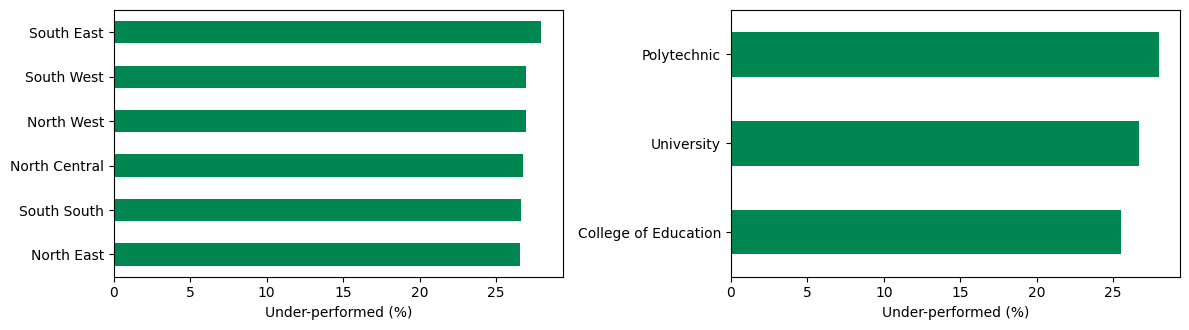

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
(df.groupby('zone')['target'].mean()*100).sort_values().plot.barh(ax=axes[0], color='#008751'); axes[0].set_xlabel('Under-performed (%)'); axes[0].set_ylabel('')
(df.groupby('institution_type')['target'].mean()*100).sort_values().plot.barh(ax=axes[1], color='#008751'); axes[1].set_xlabel('Under-performed (%)'); axes[1].set_ylabel('')
plt.tight_layout(); plt.show()

## 6. The 75% attendance requirement

In [8]:
below = df['attendance_rate'] < 75
pd.DataFrame({'records': below.value_counts(), 'under-performed (%)': (df.groupby(below)['target'].mean()*100).round(1)}).rename(index={True:'Below 75%', False:'75% or above'})

,records,under-performed (%)
attendance_rate,,
75% or above,3805,9.2
Below 75%,1978,61.0


## Takeaways for sprint 2
- All three indicators separate the two outcomes, CA score most strongly.
- The classes are unbalanced (about one record in four under-performs), so accuracy alone would flatter a lazy model. Sprint 2 therefore uses balanced class weights and selects on F1.
- Zone and institution type are kept for reporting only. They are not model inputs, in line with the three-indicator scope.